# Can AI find acquisition candidates in the U.S. and Canada?

An acquisition search begins with a description of the business a buyer wants to find. A buyer that already owns a laboratory might ask for a regional company that checks the accuracy of pressure gauges and temperature probes. The first job is to build a short list of distinct operating businesses and gather enough evidence to decide which ones deserve a closer look.

The analyst could start with an accreditation directory. A listing can lead to a document describing exactly what a laboratory can calibrate and where it does the work. The analyst then has to find the company behind the laboratory. A lab may have its own name and location while operating as a branch of a much larger company.

### An illustrative sourcing brief

Suppose an analyst finds a shop in Ohio whose website lists pressure and temperature calibration. The address is for a staffed lab and the shop sells its services to other manufacturers. The shop fits the service and location requirements. If its current ownership is also documented as independent, it can go forward for an initial review.

Now suppose the shop's old name still appears in search results, but a larger company bought the lab and operates it at the same address. Both pages can be correct about the services. The analyst needs something different for the ownership question, such as an acquisition announcement or a current company page identifying the lab as a branch. Keeping both names on the list would give the analyst two leads for one operation.

Some shops disclose little about who owns them. In those cases an analyst can carry the business forward as a lead with a question attached. That lets the sourcing team distinguish a company it should rule out from one it should check by asking for more information. The same logic applies to financials. An old contract value can indicate that the company has done work for a customer, while an income statement or dated transaction disclosure would answer a different question about revenue.

A directory gives an analyst a starting list with an explicit scope. Searching the web can turn up businesses outside that list and reveal ownership changes the directory was never designed to track. A model can do either job. It can search from an acquisition brief, or it can start from a directory list and look for evidence to prioritize each company. Once a candidate is known, the model can also prepare a short profile from public pages or from documents supplied by the analyst.

This study asks how often those approaches produce a candidate that passes the public-evidence screen, and which company facts the models can recover when researching the same companies.

## Study summary

On six real-world sourcing briefs and 24 shared company profiles, GPT-6.1 Sol and GPT-6 Luna found **7 distinct businesses outside the starting list that met our public-evidence screen**. That screen required positive evidence of the right service, a local operating site and independence. Each model flagged ownership as unresolved for every new lead that eventually passed. A reviewer had to finish that step.

The starting directory yielded 5 verified slots out of 60, and both models kept those five when they started from it. Open search returned 6 verified slots with Sol and 5 with Luna. On the shared company profiles the models matched 137 and 139 of 146 frozen fields from web search. With source packets, Sol matched 144 of 146. Luna matched 107 of 146 under the original parser and 143 of 146 when we removed the trailing tag that made six otherwise complete profiles unreadable. That puts both models near the maximum on the supplied evidence.

The comparison uses a small starting list in Michigan, Ohio, Ontario and Québec, and some public facts predate the models' cutoffs. We measured model working time. An analyst time comparison remains unmeasured.

## Contents

- [1. Sources and acquisition briefs](#1-sources-and-acquisition-briefs)
- [2. Discovery and company research](#2-discovery-and-company-research)
- [3. Shortlists and company profiles](#3-shortlists-and-company-profiles)
- [4. Worked examples and errors](#4-worked-examples-and-errors)
- [5. Limits of a public-data screen](#5-limits-of-a-public-data-screen)
- [6. Reproduction](#6-reproduction)
- [7. Future work and further reading](#7-future-work-and-further-reading)

```mermaid
flowchart LR
    briefs["3 briefs × 2 markets<br/>6 sourcing tasks"] --> dir["Public source list<br/>24 known businesses"]
    briefs --> web["Sol and Luna via codex exec<br/>12 searches from brief"]
    dir --> base["Filter and rank<br/>6 lists"]
    dir --> dirai["Sol and Luna via codex exec<br/>12 searches from list"]
    base --> review["Pool names and verify eligibility<br/>up to 300 ranked slots"]
    web --> review
    dirai --> review
    dir --> names["24 shared businesses<br/>12 per market"]
    names --> search["Sol and Luna via codex exec<br/>16 calls with web search"]
    names --> packet["Sol and Luna via codex exec<br/>16 calls with identical evidence"]
    search --> marks["96 profiles expected<br/>score against frozen facts"]
    packet --> marks
    review --> results["Shortlist and profile comparisons"]
    marks --> results
```

The Cincinnati lab formerly known as Alliance Calibration takes two routes through the study. When it appears in a sourcing list, the reviewer checks whether the operating lab can be acquired separately under the brief. When the models receive it by name in the company-research test, the task is to explain the services and identify the change in control. A profile can get that research right while leaving Alliance off an independent-company shortlist.

## 1. Sources and acquisition briefs

We used Michigan and Ohio for the U.S. briefs and Ontario and Québec for the Canadian briefs. Each geography got the same three service requirements. A calibration provider had to offer work to outside customers. For fire alarms, the test focused on companies that inspect or test commercial building systems and maintain or repair those same systems.

| Brief | What the analyst needs to verify | Easy mistake |
| --- | --- | --- |
| PT | The lab calibrates industrial instruments that measure pressure **and** temperature | A company sells pressure gauges and publishes a temperature-only calibration scope |
| DE | The lab calibrates dimensional instruments such as gauges **and** electrical instruments | An accredited facility calibrates only dimensional gauges |
| FA | The company inspects or tests **and** maintains or repairs commercial fire alarm systems | The company monitors alarms or inspects extinguishers |

These service pairs make a shortlist harder to verify than a keyword match. A customer who needs one supplier to calibrate both kinds of instruments still has to shop for a second vendor when the first one offers only half the work. We choose the conditions before seeing the responses. The same rule applies when a company offers several fire protection services and a site lists those services together without saying which systems the technicians inspect or maintain.

We read laboratory scopes and commercial service pages for service and location evidence. Certification directories help find labs or fire alarm providers in each geography. The publication date, access date, URL and brief factual paraphrase are saved with each research case. We used corporate records and acquisition disclosures where available. The Ohio Secretary of State explains that the state search supplies statutory-agent information and that its office does not maintain ownership lists. The Québec enterprise register offers establishment addresses and declared ultimate beneficiaries, and Corporations Canada publishes selected ownership-control information for federal business corporations. [Ohio business search guidance](https://www.ohiosos.gov/business/ohio-business-roadmap/frequently-asked-questions) · [Québec enterprise register](https://www.quebec.ca/entreprises-et-travailleurs-autonomes/obtenir-renseignements-entreprise/recherche-registre-entreprises/acceder-registre-entreprises) · [Corporations Canada disclosure](https://ised-isde.canada.ca/site/corporations-canada/en/how-find-information-about-individuals-significant-control)

An operating site identifies where work is performed. A statutory agent can give a business an address in a jurisdiction without operating a lab or service branch there. We used operating addresses and checked alternate names against source descriptions. For Québec, the web instructions allowed French and English terms such as *étalonnage*, *pression*, and *entretien de systèmes d’alarme incendie*. A company needed dated or current evidence of an in-region site for a verified discovery slot.

The 24 research cases span both sectors and include specialties with partial service evidence, acquired brands, and companies whose ownership is difficult to establish. These were selected for a pilot that exercises the screening rules. Their mix is not a random sample of companies in the four jurisdictions. The table in the notebook shows the operating city, sector, reference service labels and public ownership classification. [U.S. data](data/us_profiles.json) · [Canadian data](data/ca_profiles.json)

The settings below select six briefs, 12 public-company packets from each market and up to ten names per shortlist. The replay switches off fresh model calls.

In [1]:
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import hashlib
import json
import re
import unicodedata

DATA = Path("data")
MODELS = ("gpt-6.1-sol", "gpt-6-luna")
LIVE = False
N_BRIEFS = 6
N_PROFILES_PER_COUNTRY = 12
BATCH_SIZE = 3
SHORTLIST_SIZE = 10
REGIONS = {"US": ("MI", "OH"), "CA": ("ON", "QC")}
GEOGRAPHY = {
    "US": "Michigan or Ohio, United States",
    "CA": "Ontario or Québec, Canada",
}
AS_OF = "2026-11-17"
SERVICES = {
    "pressure": "industrial pressure calibration",
    "temperature": "industrial temperature calibration",
    "dimensional": "industrial dimensional or precision gauge calibration",
    "electrical": "industrial electrical instrument calibration",
    "fire_alarm_inspection": "inspection or testing of commercial building fire alarm systems",
    "fire_alarm_maintenance": "maintenance or repair of commercial building fire alarm systems",
}
BRIEF_TYPES = {
    "PT": ("calibration", ("pressure", "temperature")),
    "DE": ("calibration", ("dimensional", "electrical")),
    "FA": ("fire_alarm", ("fire_alarm_inspection", "fire_alarm_maintenance")),
}
BRIEFS = [
    {"id": f"{country}-{code}", "country": country, "sector": sector, "needed": needed}
    for country in REGIONS
    for code, (sector, needed) in BRIEF_TYPES.items()
][:N_BRIEFS]


def read_json(filename):
    return json.loads((DATA / filename).read_text(encoding="utf-8-sig"))


def name_key(name):
    decomposed = unicodedata.normalize("NFKD", name.casefold())
    unaccented = "".join(c for c in decomposed if not unicodedata.combining(c))
    words = re.findall(r"[a-z0-9]+", unaccented)
    while words and words[-1] in {"inc", "incorporated", "llc", "ltd", "limited", "corp", "corporation", "ltee"}:
        words.pop()
    return " ".join(words)


def canonical_json(value):
    return json.dumps(value, ensure_ascii=False, sort_keys=True, indent=2)


def directory_results(brief, profiles):
    rows = [
        entry for entry in profiles
        if entry["country"] == brief["country"] and entry["sector"] == brief["sector"]
    ]
    ordered = sorted(rows, key=lambda entry: (-len(set(brief["needed"]) & set(entry["services"])), entry["id"]))
    return ordered[:SHORTLIST_SIZE]


def discovery_prompt(brief, arm, profiles):
    required = " AND ".join(SERVICES[service] for service in brief["needed"])
    condition = "Find companies by searching the public web."
    if arm == "directory-first":
        entries = [
            {field: row[field] for field in ("id", "company", "city", "region", "services")}
            for row in directory_results(brief, profiles)
        ]
        condition = (
            "Start from the bounded public-source list below. Return only businesses in this list. "
            "Use web search to verify and prioritize them.\n"
            + canonical_json(entries)
        )
    french = "\nUse English and French search terms where useful, especially for Québec." if brief["country"] == "CA" else ""
    return f"""You are doing first-pass acquisition sourcing. Use only free public information as of {AS_OF}.
Find independent operating businesses with a staffed operating site in {GEOGRAPHY[brief['country']]} that offer {required}.
For calibration, the service must be offered to external customers. For fire alarm, exclude monitoring-only providers.
Rank up to {SHORTLIST_SIZE} distinct operating businesses by evidenced fit. Exclude companies positively shown as part of a larger group.
If ownership is unclear, you may list the business as a follow-up lead and mark control as unresolved. A company being active,
staffed by founders, or privately held alone does not establish independence from a group. Keep separate aliases and branch locations together.
Aim for no more than 12 search or page operations. Use the built-in public web tool. Do not contact businesses, use private data,
or estimate financials. Distinguish an operating site from a registered office. Cite a public direct URL and brief evidence.
{french}
{condition}
Return one JSON object, no Markdown. Shape:
{{"candidates":[{{"company":"business name","city":"operating city","region":"two-letter region","site_url":"https://...",
"service_evidence":{{{', '.join(f'"{field}":{{"url":"https://...","detail":"short supporting fact"}}' for field in brief["needed"])}}},
"control":"independent or unresolved","control_url":null,"control_detail":"short supporting fact or what is missing"}}]}}
"""


def research_prompt(entries, arm):
    item_fields = ("id", "company", "region", "sector")
    inputs = []
    for entry in entries:
        item = {key: entry[key] for key in item_fields}
        if arm == "packet":
            item["sources"] = [
                {key: source[key] for key in ("url", "title", "published", "excerpt")}
                for source in entry["sources"]
            ]
        inputs.append(item)
    search_instruction = (
        "Use only the supplied source packets. Report missing facts as unknown."
        if arm == "packet" else
        "Use the built-in public web search. Aim for no more than 12 search or page operations across this batch. "
        "Use English and French terms where useful."
    )
    return f"""Research these specific operating businesses for a first-pass acquisition screen as of {AS_OF}.
{search_instruction}
For each ID identify the operating city and region for the supplied jurisdiction. Only mark a service yes if a public
source supports the exact service at the business. Mark no when evidence explicitly rules it out, otherwise unknown.
For calibration, external customers are required. For fire alarms, maintenance includes repair, but monitoring alone
does not count. Use the following identifiers: {canonical_json(SERVICES)}.
Answer all four calibration services for calibration companies, or both fire_alarm services for fire-alarm companies.
Mark control group if the operating business is positively shown to belong to a larger corporate group, independent if
credible public evidence affirmatively states independent, family, employee or owner operation without indicating
a parent, otherwise unresolved. Privately held alone, director names and the absence of deal news are insufficient.
For financials use only a sourced figure with its period, currency and scope. If unavailable, use null. Distinguish
the target's financials from a parent, contract or transaction price. Every asserted field needs a direct source URL
and short supporting fact where applicable. Do not include personal addresses or nonpublic information.
Return one JSON object, no Markdown. Shape:
{{"profiles":[{{"id":"provided ID","city":"operating city or null","region":"two-letter or null","site_url":null,
"services":{{"service_id":{{"status":"yes/no/unknown","url":null,"detail":"brief evidence"}}}},
"control":"independent/group/unresolved","control_url":null,"control_detail":"brief evidence",
"revenue":null,"ebitda":null}}]}}
Inputs:
{canonical_json(inputs)}
"""


def load_profiles():
    return [
        row
        for filename in ("us_profiles.json", "ca_profiles.json")
        for row in read_json(filename)[:N_PROFILES_PER_COUNTRY]
    ]


def jobs_for(stage, profiles=()):
    if stage == "discovery":
        for arm in ("web", "directory-first"):
            for brief in BRIEFS:
                for model in MODELS:
                    yield model, discovery_prompt(brief, arm, profiles), True, f"discovery/{arm}/{brief['id']}"
    elif stage == "research":
        for arm in ("web", "packet"):
            for first in range(0, len(profiles), BATCH_SIZE):
                batch = profiles[first:first + BATCH_SIZE]
                for model in MODELS:
                    yield model, research_prompt(batch, arm), arm == "web", f"research/{arm}/{batch[0]['id']}"
    else:
        raise ValueError(f"Unknown stage {stage!r}")


def run_jobs(jobs, live=LIVE, concurrency=4):
    if not live:
        return [request_model(*job, live=False) for job in jobs]
    with ThreadPoolExecutor(max_workers=concurrency) as pool:
        task_by_future = {pool.submit(request_model, *job, live=True): job for job in jobs}
        for future in as_completed(task_by_future):
            job = task_by_future[future]
            row = future.result()
            print(job[0], job[3], row.get("error") or "received", flush=True)
        return [future.result() for future in task_by_future]


def parse_reply(row, field, *, trim_final_tag=False):
    if row.get("error"):
        return None
    raw = row["response"]["text"].strip()
    if trim_final_tag:
        raw = re.sub(r"</final>?$", "", raw).rstrip()
    fenced = re.fullmatch(r"```(?:json)?\s*(.+?)\s*```", raw, flags=re.DOTALL | re.IGNORECASE)
    try:
        parsed = json.loads(fenced.group(1) if fenced else raw)
    except (ValueError, TypeError):
        return None
    values = parsed.get(field) if isinstance(parsed, dict) else None
    if not isinstance(values, list) or any(not isinstance(item, dict) for item in values):
        return None
    if field == "candidates" and (
        len(values) > SHORTLIST_SIZE
        or any(not isinstance(item.get("company"), str) or not item["company"].strip() for item in values)
    ):
        return None
    return values

In [2]:
import pandas as pd
from IPython.display import display
profiles = load_profiles()
display(pd.DataFrame(profiles)[["id", "company", "region", "city", "sector", "services", "control"]])

,id,company,region,city,sector,services,control
0,US-01,"A & A Calibrations, LLC",MI,Riverview,calibration,"[dimensional, temperature]",unresolved
1,US-02,Pyro Service Company,MI,Madison Heights,calibration,[temperature],unresolved
2,US-03,True Trace Metrology,MI,Rochester Hills,calibration,"[pressure, temperature, electrical]",unresolved
3,US-04,Cal-Cert Wayland,MI,Wayland,calibration,"[pressure, temperature, dimensional, electrical]",group
4,US-05,Total Cal,OH,Mentor,calibration,"[pressure, temperature, dimensional, electrical]",unresolved
5,US-06,Alliance Calibration,OH,Cincinnati,calibration,"[pressure, temperature, dimensional, electrical]",group
6,US-07,e2b calibration,OH,Mentor,calibration,"[pressure, temperature, dimensional, electrical]",group
7,US-08,Fire Defense Equipment Company Inc.,MI,Royal Oak,fire_alarm,"[fire_alarm_inspection, fire_alarm_maintenance]",independent
8,US-09,"Gene Ptacek & Son Fire Equipment Company, Inc.",OH,Cleveland,fire_alarm,"[fire_alarm_inspection, fire_alarm_maintenance]",independent
9,US-10,Rogers Fire Protection Co.,OH,Marengo,fire_alarm,"[fire_alarm_inspection, fire_alarm_maintenance]",independent


## 2. Discovery and company research

### What each approach can see

The directory baseline searches the same small public-source list used for the research test. It first filters the list to the right country and industry, then ranks by the number of required service facts in each entry. The two models that start with the directory receive the ranked names and service fields and can search for evidence to improve the ordering or leave a company out. The open-web models get only the brief and are free to find names outside the list. The baseline can fill at most the number of directory entries in its sector. This is a test against a bounded starting list. The number of firms in eligible accreditation directories is substantially larger. [A2LA directory](https://customer.a2la.org/?event=directory.index) · [ANAB directories](https://anab.ansi.org/directories/) · [UL fire-alarm service categories](https://www.ul.com/services/fire-alarm-service-provider-certification-and-compliance) · [ULC listing categories](https://canada.ul.com/ulcprograms/fireandsecurityalarmcertificateprograms/certificateserviceprocedures/)

For company research, both models get the same companies by name, across eight batches of three. They answer the same questions twice. With search enabled a model must find and interpret its own sources. With search disabled, each model gets the same short evidence packet and identifies what the supplied material supports. The packet comparison tests extraction from prepared evidence. It is easier to consult a short paraphrase than to interpret a lengthy accreditation schedule. The difference between web and packet therefore reflects evidence availability, source selection and extraction together.

| Model | CLI model ID | Provider and access | Published size and precision | Settings | Reason for inclusion |
| --- | --- | --- | --- | --- | --- |
| GPT-6.1 Sol | `gpt-6.1-sol`, dated revision unavailable in CLI replies | OpenAI, `codex exec` | Unpublished | Medium reasoning, live web or search disabled by task | General-purpose reference for open research |
| GPT-6 Luna | `gpt-6-luna`, dated revision unavailable in CLI replies | OpenAI, `codex exec` | Unpublished | Medium reasoning, same instructions and search settings | Compact model for repeated screening work |

For both models the prompt asks them to aim for up to 12 search or page operations in a task. This is an instruction. The CLI records web operations but does not impose a hard cap. Each call uses the same public-web setting for its arm and receives an isolated working directory. The user can inspect the prompt and full final response in the per-request cache. [Sol model page](https://developers.openai.com/api/docs/models/gpt-6.1-sol) · [Luna model page](https://developers.openai.com/api/docs/models/gpt-6-luna)

```mermaid
flowchart TD
    a["Acquisition brief"] -->|"From brief, or names from directory"| b["Sol / Luna via codex exec<br/>parallel runs<br/>ranked names and public citations"]
    p["Batch of 3 known companies"] -->|"Names and regions"| c["Sol / Luna via codex exec<br/>parallel live searches<br/>3 company profiles"]
    p -->|"Same dated evidence for both models"| d["Sol / Luna via codex exec<br/>parallel runs, search disabled<br/>3 company profiles"]
    b -->|"Wait for lists, pool company names"| v["Alias matching and evidence adjudication"]
    c -->|"Wait for profiles"| s["Field-by-field scoring"]
    d -->|"Wait for profiles"| s
```

There is one model call per arm, model and brief for discovery. A research call handles three companies at once, so the research denominator is the number of returned company profiles and fields. A call that times out can affect three profiles. Our models do not read each other's answers.

### What counts as a useful shortlist entry

A **verified fit** has positive public evidence for an operating site, all requested services, and independence. For a local or family business, affirmative language about current ownership can support the last criterion. If sources indicate a sale, merger or branch relationship, examine what transferred and how the business is operating now. If a lead is real and has an unresolved service, site or ownership question, it earns an unresolved label. A name whose identity the reviewers cannot match is tracked separately.

Each list gets ten slots. If a method returns only five names and three pass, the result is three verified fits out of ten slots. The five missing slots show how much of the requested shortlist was delivered. When a model includes an unresolved lead that reviewers can verify with additional evidence, the slot can still count. This measures the value of a returned name to a reviewer. The number is not a claim that the model itself had already completed the evidence check. We also count distinct verified companies found outside the source list. The same company can fit two briefs and use a slot in each, but it is only one new company in a country-level additions count.

The research score uses one field for the city, another for the state or province, one for control and one for each service. A fire-alarm example with a correct city, region, and two service fields but a wrong ownership label earns four of five. A cell earns credit for saying unknown if a field has no supporting evidence in the reference. A public statement discovered outside the packet may add useful information. Compare those claims to their cited evidence before treating them as verified improvements.

The runner retrieves the exact response for each prompt from its request hash. It also contains the CLI and trace paths for an explicitly enabled fresh run.

In [3]:
import datetime as dt
import hashlib
import json
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import time

import requests

NOTEBOOK = "46-us-canada-deal-sourcing"
LANGFUSE_HOST = os.environ.get("LANGFUSE_HOST", "http://localhost:3300").rstrip("/")
LANGFUSE_AUTH = (os.environ.get("LANGFUSE_PUBLIC_KEY", ""), os.environ.get("LANGFUSE_SECRET_KEY", ""))


def _langfuse_running():
    if not all(LANGFUSE_AUTH):
        return False
    try:
        return requests.get(f"{LANGFUSE_HOST}/api/public/health", timeout=2).ok
    except requests.RequestException:
        return False


def trace_call(cache_key, name, model, request, response, start, end, usage=None, error=None, enabled=False):
    """Send exactly one fresh generation to the optional local Langfuse instance."""
    if not enabled:
        return
    def attr(k, v):
        return {"key": k, "value": {"stringValue": v if isinstance(v, str) else json.dumps(v, default=str)}}
    attrs = [attr("langfuse.observation.type", "generation"), attr("langfuse.observation.model.name", model),
             attr("langfuse.observation.input", request), attr("langfuse.observation.output", response),
             attr("langfuse.trace.name", f"46 {name}"),
             {"key": "langfuse.trace.tags", "value": {"arrayValue": {"values": [{"stringValue": "nb46"}]}}},
             attr("langfuse.environment", "notebook"), attr("langfuse.trace.metadata.notebook", NOTEBOOK),
             attr("langfuse.trace.metadata.cache_key", cache_key)]
    if usage:
        attrs.append(attr("langfuse.observation.usage_details", usage))
    if error:
        attrs.extend([attr("langfuse.observation.level", "ERROR"), attr("langfuse.observation.status_message", error)])
    span = {"traceId": hashlib.sha256(f"{NOTEBOOK}|{cache_key}".encode()).hexdigest()[:32],
            "spanId": hashlib.sha256(f"{NOTEBOOK}|{cache_key}|gen|0".encode()).hexdigest()[:16],
            "name": name, "kind": 1, "attributes": attrs,
            "startTimeUnixNano": str(int(start.timestamp() * 1e9)),
            "endTimeUnixNano": str(int(end.timestamp() * 1e9))}
    body = {"resourceSpans": [{"resource": {"attributes": [attr("service.name", "experiment-notebooks")]},
                               "scopeSpans": [{"scope": {"name": NOTEBOOK}, "spans": [span]}]}]}
    try:
        requests.post(f"{LANGFUSE_HOST}/api/public/otel/v1/traces", json=body, auth=LANGFUSE_AUTH, timeout=10)
    except requests.RequestException:
        pass


def _codex_executable():
    # Launch the npm entry point directly to preserve quotes in TOML overrides.
    wrapper = shutil.which("codex.cmd") if os.name == "nt" else None
    node = shutil.which("node.exe") if wrapper else None
    if wrapper and node:
        entry = Path(wrapper).parent / "node_modules" / "@openai" / "codex" / "bin" / "codex.js"
        if entry.is_file():
            return [node, str(entry)]
    executable = shutil.which("codex.exe" if os.name == "nt" else "codex")
    if executable:
        return [executable]
    raise FileNotFoundError("Codex CLI was not found on PATH")


def _parse_codex_events(stdout):
    """Keep only final agent messages, native web-search events and turn usage."""
    messages, web_events, usage = [], [], {}
    for line in stdout.splitlines():
        try:
            event = json.loads(line)
        except (ValueError, TypeError):
            continue
        if not isinstance(event, dict):
            continue
        if event.get("type") == "item.completed":
            item = event.get("item") or {}
            if item.get("type") == "agent_message" and isinstance(item.get("text"), str):
                messages.append(item["text"])
            elif item.get("type") == "web_search":
                # Search metadata is evidence; exclude arbitrary tool results and shell output.
                web_events.append({k: item[k] for k in ("type", "query", "action") if k in item})
        elif event.get("type") == "turn.completed" and isinstance(event.get("usage"), dict):
            usage = event["usage"]
    return {"text": messages[-1] if messages else "", "web_events": web_events, "usage": usage}


def request_model(model, prompt, web, task_id, *, live=False):
    """Replay the exact request, or explicitly opt in to a fresh Codex call on a cache miss."""
    if not isinstance(web, bool):
        raise TypeError("web must be a bool")
    request = {"model": model, "prompt": prompt, "web": web, "task_id": task_id,
               "reasoning_effort": "medium", "web_search": "live" if web else "disabled",
               "cli": "codex exec", "sandbox": "read-only", "approval_policy": "never",
               "ignore_user_config": True, "ephemeral": True, "timeout_seconds": 600,
               "cache_schema": 3}
    canonical = json.dumps(request, sort_keys=True, ensure_ascii=False, separators=(",", ":"))
    key = hashlib.sha256(canonical.encode("utf-8")).hexdigest()
    cache_path = Path("data/calls") / f"{key}.json"
    if cache_path.exists():
        row = json.loads(cache_path.read_text(encoding="utf-8"))
        if row.get("key") != key or row.get("request") != request:
            raise ValueError(f"Cache request mismatch: {cache_path}")
        return row
    if not live:
        raise FileNotFoundError(f"No cached response for {task_id} ({model}, web={web}): {cache_path}. Set live=True to authorize a fresh call.")
    langfuse_on = _langfuse_running()
    start = dt.datetime.now(dt.timezone.utc)
    t0 = time.monotonic()
    response = {"text": "", "web_events": [], "usage": {}}
    error = None
    try:
        with tempfile.TemporaryDirectory(prefix="nb46-codex-") as tmp:
            args = [*_codex_executable(), "exec", "--json", "--skip-git-repo-check", "--ephemeral",
                    "--ignore-user-config", "--sandbox", "read-only", "--model", model,
                    "-c", 'approval_policy="never"', "-c", 'model_reasoning_effort="medium"',
                    "-c", f'web_search="{request["web_search"]}"', "-"]
            proc = subprocess.run(args, input=prompt, stdout=subprocess.PIPE, stderr=subprocess.PIPE,
                                  text=True, encoding="utf-8", errors="replace", cwd=tmp,
                                  timeout=request["timeout_seconds"], check=False)
            response = _parse_codex_events(proc.stdout)
            if proc.returncode:
                error = f"codex_exit_{proc.returncode}"
            elif not response["text"]:
                error = "empty_final_message"
    except subprocess.TimeoutExpired:
        error = "timeout"
    except (OSError, ValueError) as exc:
        error = f"launch_error:{type(exc).__name__}"
    end = dt.datetime.now(dt.timezone.utc)
    row = {"key": key, "request": request, "response": response, "error": error,
           "elapsed_seconds": round(time.monotonic() - t0, 3)}
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", dir=cache_path.parent, delete=False) as file:
        file.write(json.dumps(row, ensure_ascii=False, indent=2) + "\n")
        staged_path = Path(file.name)
    staged_path.replace(cache_path)
    u = response["usage"]
    # Codex's input_tokens includes its cached_input_tokens; avoid counting those twice in Langfuse.
    trace_usage = ({"input": max(0, u.get("input_tokens", 0) - u.get("cached_input_tokens", 0)),
                    "input_cache_read": u.get("cached_input_tokens", 0),
                    "output": max(0, u.get("output_tokens", 0) - u.get("reasoning_output_tokens", 0)),
                    "output_reasoning": u.get("reasoning_output_tokens", 0)}
                   if u else None)
    trace_call(key, "deal sourcing", model, request, response, start, end, usage=trace_usage, error=error, enabled=langfuse_on)
    return row

The next cells check result shape, adjudicate aliases and service fit, and score the same saved profile fields for both evidence conditions.

In [4]:
from urllib.parse import urlsplit

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "figure.dpi": 144, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.labelcolor": "#304051", "text.color": "#192b39", "axes.titleweight": "bold",
    "grid.color": "#dce5eb", "font.size": 10, "savefig.bbox": "tight",
})
COLOURS = {"gpt-6.1-sol": "#286278", "gpt-6-luna": "#a85227", "directory": "#66707e"}
DISPLAY = {"gpt-6.1-sol": "Sol", "gpt-6-luna": "Luna", "directory": "Directory"}
MUNICIPALITIES = {
    "north york": "toronto", "toronto north york": "toronto",
    "scarborough": "toronto", "toronto scarborough": "toronto",
    "saint laurent": "montreal", "st laurent": "montreal", "lachine": "montreal",
    "saint hubert": "longueuil", "longueuil saint hubert": "longueuil",
}


def city_key(city):
    key = name_key(city or "")
    return MUNICIPALITIES.get(key, key)


def url_key(url):
    if not isinstance(url, str):
        return ""
    parts = urlsplit(url)
    if parts.scheme not in {"http", "https"} or not parts.netloc:
        return ""
    return f"{parts.netloc.lower().removeprefix('www.')}{parts.path.rstrip('/')}"


def leads_table(profiles, calls, novel, adjudications):
    lookup = {}
    for entry in [*profiles, *novel]:
        entry = {**entry, **adjudications.get(entry["id"], {})}
        for name in [entry["company"], *entry["aliases"]]:
            key = entry["country"], name_key(name)
            if key in lookup and lookup[key]["id"] != entry["id"]:
                raise ValueError(f"Ambiguous entity alias: {name}")
            lookup[key] = entry
    rows = []

    def add_list(brief, arm, model, candidates, error=None):
        seen = set()
        frame_ids = {entry["id"] for entry in directory_results(brief, profiles)}
        for rank in range(1, SHORTLIST_SIZE + 1):
            candidate = candidates[rank - 1] if rank <= len(candidates) else {}
            company = candidate.get("company")
            entry = lookup.get((brief["country"], name_key(company))) if company else None
            dedupe = (entry.get("operating_group") or entry["id"]) if entry else (name_key(company) if company else None)
            if error:
                verdict = "unreadable"
            elif not company:
                verdict = "empty"
            elif dedupe in seen:
                verdict = "duplicate"
            elif not entry:
                verdict = "unmatched"
            elif arm == "directory-first" and entry["id"] not in frame_ids:
                verdict = "outside frame"
            elif entry["control"] == "group" or entry.get("hard_exclusion") or entry["sector"] != brief["sector"]:
                verdict = "ruled out"
            elif (
                entry["control"] == "independent"
                and entry["region"] in REGIONS[brief["country"]]
                and entry.get("city")
                and set(brief["needed"]) <= set(entry["services"])
            ):
                verdict = "verified fit"
            else:
                verdict = "unresolved"
            if dedupe:
                seen.add(dedupe)
            rows.append({
                "brief": brief["id"], "country": brief["country"], "arm": arm, "model": model,
                "rank": rank, "submitted_name": company, "canonical_id": entry["id"] if entry else None,
                "city": entry.get("city") if entry else None, "verdict": verdict,
                "new_to_frame": entry["id"] not in frame_ids if entry else False,
                "model_control": candidate.get("control"),
            })

    by_id = {brief["id"]: brief for brief in BRIEFS}
    for brief in BRIEFS:
        add_list(brief, "directory", "directory", directory_results(brief, profiles))
    for call in calls:
        request = call["request"]
        _, arm, brief_id = request["task_id"].split("/")
        candidates = parse_reply(call, "candidates")
        add_list(by_id[brief_id], arm, request["model"], candidates or [], candidates is None)
    return pd.DataFrame(rows)


def research_tables(profiles, calls, *, trim_final_tag=False):
    by_id = {entry["id"]: entry for entry in profiles}
    profile_rows, field_rows = [], []
    for call in calls:
        request = call["request"]
        _, arm, first_id = request["task_id"].split("/")
        country, first_number = first_id.split("-")
        batch_ids = [
            f"{country}-{number:02}"
            for number in range(int(first_number), int(first_number) + BATCH_SIZE)
            if f"{country}-{number:02}" in by_id
        ]
        reply = parse_reply(call, "profiles", trim_final_tag=trim_final_tag)
        answers = {}
        duplicates = set()
        for item in reply or []:
            item_id = item.get("id")
            if isinstance(item_id, str):
                if item_id in answers:
                    duplicates.add(item_id)
                answers[item_id] = item

        for profile_id in batch_ids:
            truth = by_id[profile_id]
            answer = answers.get(profile_id, {})
            services = answer.get("services")
            allowed = (*BRIEF_TYPES["PT"][1], *BRIEF_TYPES["DE"][1]) if truth["sector"] == "calibration" else BRIEF_TYPES["FA"][1]
            readable = (
                isinstance(services, dict) and profile_id not in duplicates
                and answer.get("control") in ("group", "independent", "unresolved")
                and (answer.get("city") is None or isinstance(answer["city"], str))
                and (answer.get("region") is None or isinstance(answer["region"], str))
                and all(
                    isinstance(services.get(field), dict)
                    and services[field].get("status") in ("yes", "no", "unknown")
                    for field in allowed
                )
            )
            base = {"arm": arm, "model": request["model"], "case": profile_id, "country": truth["country"],
                    "company": truth["company"], "readable": readable}
            profile_rows.append({
                **base, "revenue": answer.get("revenue"), "ebitda": answer.get("ebitda"),
                "control_detail": answer.get("control_detail"),
            })
            known_urls = {url_key(source["url"]) for source in truth["sources"]}
            fields = [
                ("operating_city", city_key(truth["city"]), city_key(answer.get("city")) if readable else None,
                 answer.get("site_url"), bool(truth["city"])),
                ("region", truth["region"], answer.get("region") if readable else None, answer.get("site_url"), True),
                ("control", truth["control"], answer.get("control") if readable else None,
                 answer.get("control_url"), truth["control"] != "unresolved"),
            ]
            for service in allowed:
                found = service in truth["services"]
                obj = services[service] if readable else {}
                fields.append((service, "yes" if found else "unknown", obj.get("status"), obj.get("url"), found))
            for field, expected, observed, url, known in fields:
                asserted = bool(observed) and observed not in {"unknown", "unresolved"}
                citation = url_key(url)
                field_rows.append({
                    **base, "field": field, "expected": expected, "observed": observed, "known": known,
                    "agrees": readable and expected == observed,
                    "asserted": asserted, "citation": url, "has_url": asserted and bool(citation),
                    "packet_url": asserted and bool(citation) and citation in known_urls,
                })
    return pd.DataFrame(profile_rows), pd.DataFrame(field_rows)


def summarize(leads, profiles, fields, calls):
    discovery = (
        leads.assign(n=1).pivot_table(index=["country", "arm", "model"], columns="verdict",
                                     values="n", aggfunc="sum", fill_value=0)
        .reindex(columns=["verified fit", "ruled out", "unresolved", "duplicate", "outside frame",
                          "unmatched", "empty", "unreadable"], fill_value=0)
        .reset_index()
    )
    new = leads.loc[leads.verdict.eq("verified fit") & leads.new_to_frame]
    unique_new = new.groupby(["country", "arm", "model"])["canonical_id"].nunique()
    discovery["verified additions"] = [
        int(unique_new.get((row.country, row.arm, row.model), 0))
        for row in discovery.itertuples()
    ]
    stats = []
    for (country, arm, model), group in fields.groupby(["country", "arm", "model"]):
        subset = profiles.loc[(profiles.country == country) & (profiles.arm == arm) & (profiles.model == model)]
        read = group.loc[group.readable]
        known = read.loc[read.known]
        unknown = read.loc[~read.known]
        stats.append({
            "country": country, "arm": arm, "model": model,
            "profiles": len(subset), "unreadable_profiles": int((~subset.readable).sum()),
            "fields": len(group), "matched_fields": int(group.agrees.sum()),
            "readable_fields": len(read), "readable_errors": int((~read.agrees).sum()),
            "known_fields": len(known), "matched_known": int(known.agrees.sum()),
            "unknown_fields": len(unknown), "matched_unknown": int(unknown.agrees.sum()),
            "asserted_fields": int(read.asserted.sum()), "with_url": int(read.has_url.sum()),
            "with_packet_url": int(read.packet_url.sum()),
        })
    usage_rows = []
    for row in calls:
        request = row["request"]
        usage = row["response"]["usage"]
        task, arm, _ = request["task_id"].split("/")
        usage_rows.append({
            "model": request["model"], "task": task, "arm": arm, "failed": bool(row["error"]),
            "seconds": row["elapsed_seconds"], "web_events": len(row["response"]["web_events"]),
            "input_tokens": usage.get("input_tokens", 0),
            "cached_input_tokens": usage.get("cached_input_tokens", 0),
            "output_tokens": usage.get("output_tokens", 0),
        })
    return discovery, pd.DataFrame(stats), pd.DataFrame(usage_rows)


def show_discovery(discovery):
    figure_dir = Path("figures")
    figure_dir.mkdir(exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), layout="constrained", sharey=True)
    series = [("directory", "directory"), *[
        (arm, model) for arm in ("directory-first", "web") for model in MODELS
    ]]
    names = ["Directory list", "Sol with directory", "Luna with directory", "Sol web search", "Luna web search"]
    for ax, country in zip(axes, REGIONS):
        rows = discovery.loc[discovery.country.eq(country)].set_index(["arm", "model"])
        fits = [int(rows.loc[key, "verified fit"]) for key in series]
        cap = SHORTLIST_SIZE * sum(b["country"] == country for b in BRIEFS)
        ax.barh(names, [cap] * len(series), color="#edf1f4", height=.55)
        ax.barh(names, fits, color=[COLOURS[key[1]] for key in series], height=.55)
        ax.set_title("Michigan and Ohio" if country == "US" else "Ontario and Québec")
        ax.set_xlim(0, cap + 2)
        ax.set_xlabel("Verified shortlist slots")
        ax.xaxis.grid(True)
        for index, value in enumerate(fits):
            ax.text(value + .35, index, f"{value}/{cap}", va="center", fontsize=9)
    axes[0].invert_yaxis()
    fig.suptitle("Public evidence confirmed only a fraction of shortlist slots", fontsize=15, fontweight="bold")
    fig.savefig(figure_dir / "shortlist_yield.png", facecolor="white")
    plt.show()


def show_research(research):
    figure_dir = Path("figures")
    figure_dir.mkdir(exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), layout="constrained", sharex=True)
    for ax, country in zip(axes, REGIONS):
        rows = research.loc[research.country.eq(country)].set_index(["arm", "model"])
        keys = [(arm, model) for arm in ("web", "packet") for model in MODELS]
        labels = ["Sol web", "Luna web", "Sol packet", "Luna packet"]
        ratios = [rows.loc[key, "matched_fields"] / rows.loc[key, "fields"] for key in keys]
        ax.barh(labels, ratios, color=[COLOURS[key[1]] for key in keys], height=.5)
        ax.set_title("United States" if country == "US" else "Canada")
        ax.set_xlabel("Share of fields agreeing with frozen evidence")
        ax.set_xlim(0, 1.13)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.xaxis.grid(True)
        ax.invert_yaxis()
        for index, (key, ratio) in enumerate(zip(keys, ratios)):
            matched = rows.loc[key, "matched_fields"]
            total = rows.loc[key, "fields"]
            ax.text(ratio + .02, index, f"{matched}/{total}", va="center", fontsize=9)
    fig.suptitle("Six unreadable profiles lowered Luna's U.S. packet score", fontsize=15, fontweight="bold")
    fig.savefig(figure_dir / "profile_agreement.png", facecolor="white")
    plt.show()

In [5]:
profiles = load_profiles()
assert len({row["id"] for row in profiles}) == len(profiles)
assert Counter(row["country"] for row in profiles) == {"US": N_PROFILES_PER_COUNTRY, "CA": N_PROFILES_PER_COUNTRY}
novel = read_json("us_verified_leads.json") + read_json("ca_verified_leads.json")
adjudications = read_json("discovery_adjudications.json")

discovery_calls = run_jobs(jobs_for("discovery", profiles), live=LIVE)
research_calls = run_jobs(jobs_for("research", profiles), live=LIVE)
leads = leads_table(profiles, discovery_calls, novel, adjudications)
research_profiles, research_fields = research_tables(profiles, research_calls)
discovery_summary, research_summary, usage = summarize(
    leads, research_profiles, research_fields, discovery_calls + research_calls
)
repaired_profiles, repaired_fields = research_tables(profiles, research_calls, trim_final_tag=True)
_, repaired_summary, _ = summarize(leads, repaired_profiles, repaired_fields, [])
assert len(leads) == SHORTLIST_SIZE * (len(BRIEFS) + len(discovery_calls))
assert len(research_profiles) == len(profiles) * len(MODELS) * 2
for filename, frame in [
    ("shortlist_slots.csv", leads),
    ("shortlist_summary.csv", discovery_summary),
    ("research_fields.csv", research_fields),
    ("research_profiles.csv", research_profiles),
    ("research_summary.csv", research_summary),
    ("research_summary_trimming_final_tag.csv", repaired_summary),
    ("call_usage.csv", usage),
]:
    frame.to_csv(DATA / filename, index=False, lineterminator="\n")

print(f"Replayed {len(discovery_calls) + len(research_calls)} measured requests.")
print("Recorded collection had US$0 in separate API spend. Codex subscription cost was not itemized.")

Replayed 56 measured requests.
Recorded collection had US$0 in separate API spend. Codex subscription cost was not itemized.


## 3. Shortlists and company profiles

### Shortlist yield

Compare the number of filled, verified slots for each method and market. The grey bar shows the same 30 slots on each side, ten for each of the three briefs. Dark bars count slots that passed after evidence review. The table also gives the reason for unfilled or unconfirmed slots and counts the unique companies that passed and were absent from the bounded list.

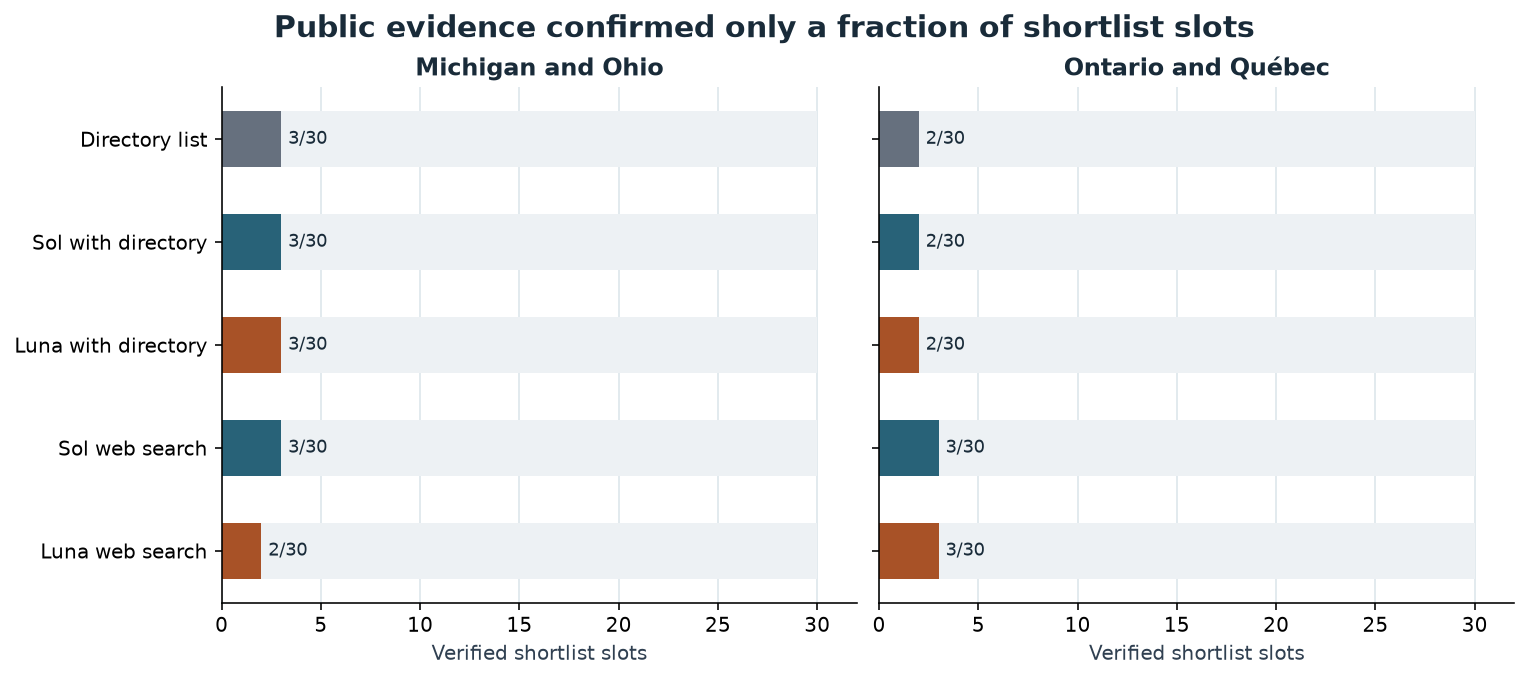

In [6]:
show_discovery(discovery_summary)

| Market   | Workflow            |   Verified |   Ruled out |   Unresolved |   Duplicate |   Empty |   Unreadable |   New companies |
|:---------|:--------------------|-----------:|------------:|-------------:|------------:|--------:|-------------:|----------------:|
| CA       | Directory list      |          2 |           5 |           11 |           0 |      12 |            0 |               0 |
| CA       | Luna with directory |          2 |           1 |            4 |           0 |      23 |            0 |               0 |
| CA       | Sol with directory  |          2 |           0 |            3 |           0 |      25 |            0 |               0 |
| CA       | Luna web search     |          3 |           1 |           16 |           0 |      10 |            0 |               2 |
| CA       | Sol web search      |          3 |           1 |            6 |           0 |      20 |            0 |               1 |
| US       | Directory list      |          3 |           5 |            9 |           2 |      11 |            0 |               0 |
| US       | Luna with directory |          3 |           1 |            3 |           0 |      23 |            0 |               0 |
| US       | Sol with directory  |          3 |           0 |            2 |           0 |      25 |            0 |               0 |
| US       | Luna web search     |          2 |           0 |           11 |           0 |      17 |            0 |               2 |
| US       | Sol web search      |          3 |           0 |            3 |           0 |      24 |            0 |               3 |

Open web search added four unique U.S. businesses and three Canadian businesses across both models. Sol returned 16 names across its six lists and produced 6 verified slots. Luna returned 33 names and produced 5 verified slots. The larger Luna lists yielded more leads that needed checking. In the U.S., both models found Fairfield Fire Protection. Their remaining verified additions were different. In Canada, each open-web arm filled three verified slots, which included Canadian Instrumentation Services Group in both runs.

When given the directory as a starting list, both models kept the same verified leads and returned shorter lists. The baseline contained ten ruled-out slots and two duplicates, while Sol with the directory returned zero ruled-out slots and Luna returned two. In this bounded comparison the models reduced the number of candidates needing review on the same starting names. They could only add new firms with the open brief. Several lists returned fewer than ten leads. Three briefs per market are enough to examine causes of failure, but the gap of one verified slot between the open-search models is too small for a general ranking.

### Accuracy against common company evidence

Compare the two web arms, then the two packet arms. The denominator is identical within each geography. The pilot has seven U.S. calibration and five fire cases, and six of each in Canada, so the U.S. has two more service fields overall. Fields whose evidence is unresolved are included because recognizing a gap changes what the reviewer has to check. The table shows the readable-only errors and agreement on unresolved fields to make that contribution visible.

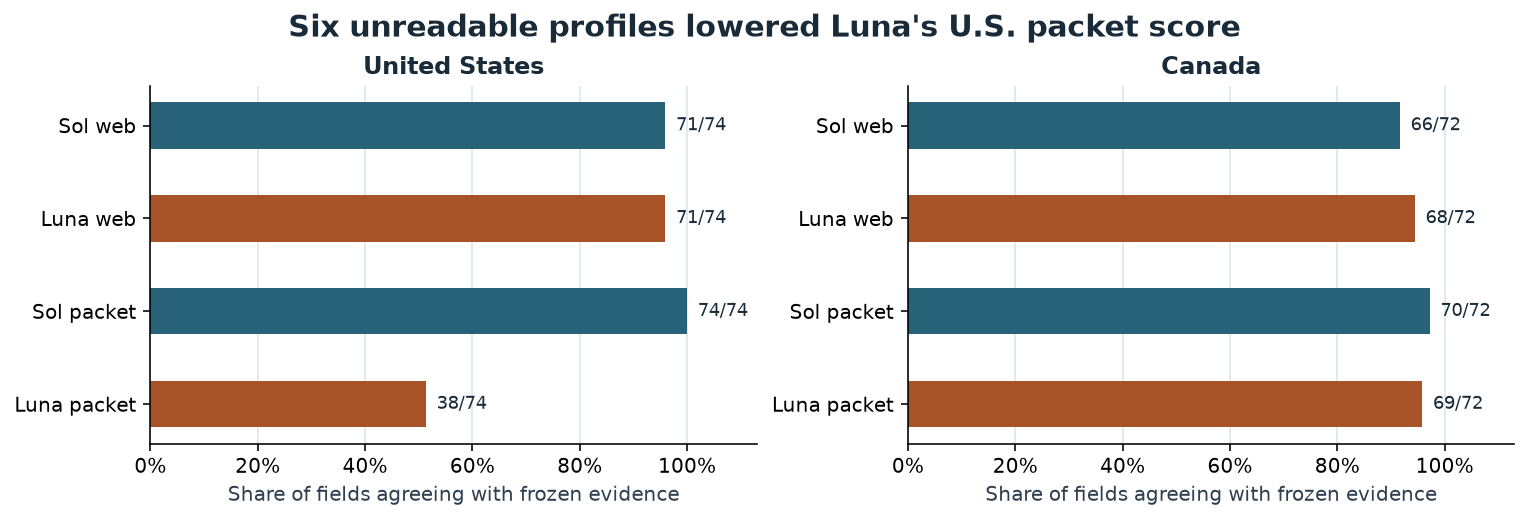

In [7]:
show_research(research_summary)

| Market   | Evidence   | Model   | Matches / fields   |   Unreadable profiles | Matches / readable   |   Readable field mismatches | Unresolved fields matched   |
|:---------|:-----------|:--------|:-------------------|----------------------:|:---------------------|----------------------------:|:----------------------------|
| CA       | packet     | Luna    | 69/72              |                     0 | 69/72                |                           3 | 12/14                       |
| CA       | packet     | Sol     | 70/72              |                     0 | 70/72                |                           2 | 12/14                       |
| CA       | web        | Luna    | 68/72              |                     0 | 68/72                |                           4 | 11/14                       |
| CA       | web        | Sol     | 66/72              |                     0 | 66/72                |                           6 | 9/14                        |
| US       | packet     | Luna    | 38/74              |                     6 | 38/38                |                           0 | 1/1                         |
| US       | packet     | Sol     | 74/74              |                     0 | 74/74                |                           0 | 11/11                       |
| US       | web        | Luna    | 71/74              |                     0 | 71/74                |                           3 | 9/11                        |
| US       | web        | Sol     | 71/74              |                     0 | 71/74                |                           3 | 9/11                        |

From the web, both models matched 71 of 74 U.S. fields. Across both markets their scores differed by 2 of 146 fields. Packet replies that could be read scored near the maximum. In the U.S., Sol got 74 of 74 and Luna got 38 of 38 on the six readable profiles. The two unreadable Luna calls each held three companies, so its overall U.S. packet score fell to 38 of 74.

Both unreadable messages held a complete JSON object followed by a final tag. One ended in `</final>` and the other in `</final`. Trimming just those terminal tags produced 74 of 74 U.S. fields for Luna and 143 of 146 across both markets. That changed the U.S. packet comparison to a tie. Across both markets, Sol matched 144 of 146 fields and Luna matched 143 after repair. One field does not separate the two models reliably. The saved replies let a reader verify both scores. [Parser sensitivity](data/research_summary_trimming_final_tag.csv)

Where both models had the same packet, most fields could be copied or left unresolved from relatively compact evidence. In open search, a mismatch can be a new fact outside the packet, a classification boundary, or a genuinely unsupported claim. A sourcing workflow needs both a usable response format and an evidence check that allows for those possibilities.

Source coverage is a different measure from agreement. All 128 assertions from Sol and all 125 from Luna in web research included URLs. A cited link tells the reviewer where to look, and a working link can still point to a page that supports a nearby service rather than the exact one in the brief. The saved field table records whether an asserted field came with a URL, and if a link in a packet reply matches a source supplied with that company. The worked cases below show where the cited page supports the claim and where reading the page changes the assessment. This pilot records source support for lead qualification and audits examples from the profile replies. The URL count measures how often the model offered a place to check.

## 4. Worked examples and errors

We selected the following cases for the decisions they illustrate. The complete set of ranked slots and fields remains in the saved tables. A case in two briefs can contribute two slots, while the same business counts once in a market-level list of additions.

### A lab that passes two service briefs

The Peterborough, Ontario, entry for Canadian Instrumentation Services Group (CA-01) pairs an accreditation-directory record with the lab's description of pressure, temperature, dimensional and electrical calibration for business customers. The company explicitly describes itself as independent and privately owned. This is affirmative public evidence for the first pass. The analyst would still confirm control with transaction diligence. [Accreditation record](https://customer.a2la.org/index.cfm?event=directory.detail&labPID=CF88E682-986D-4B36-9433-27140C3BC1C1) · [Company services and ownership](https://www.cisg.net/calibration/)

Sol's open search returned it for both Canadian calibration briefs. Luna returned it on the dimensional and electrical brief. Both directory-first runs kept it on both briefs. In the directory baseline it contributed two of the five verified shortlist slots across the two markets. This is the kind of company a good starting directory can already surface.

### A new name that still needed an ownership check

The open U.S. pressure-and-temperature brief sent to Sol requested firms with both services at an operating site in Michigan or Ohio and allowed unresolved leads. Sol returned only Grand Rapids Metrology (US-X07), with `"control":"unresolved"`. Its cited company information and service pages identified a family business and both service categories. A distributor's account also identifies the business as a fifth-generation family-owned company and names its Michigan locations. The source review therefore advanced the lead to verified fit under the pilot rubric. Grand Rapids Metrology was outside the starting list. A reviewer acting on Sol's answer would have had one lead to check and no second name from that call. [Company history](https://grmetrology.com/company/) · [Calibration services](https://grmetrology.com/accredited-calibration/) · [Distributor account](https://www.linkedin.com/posts/fairbanks-scales_metrology-industrialscales-familybusiness-activity-7482479033885159424-FThH)

This pattern held across the novel hits. Both models used the unresolved ownership label on all eight returned slots that ultimately became seven distinct verified additions. A human reviewer receiving these outputs would need to finish the same ownership step.

### End-to-end company research on Alliance Calibration

The web prompt gave the model the record below, alongside two other labs. It asked for the operating city, region, four calibration fields and control label. It asked for a public source and brief evidence for each assertion. The packet arm used these same fields and included paraphrases of the transaction and Cincinnati lab page.

```json
{"id":"US-06","company":"Alliance Calibration","region":"OH","sector":"calibration"}
```

The operating record points to a Cincinnati lab. Its current page describes pressure, temperature, dimensional and electrical work, and identifies the operation as formerly Alliance Calibration. The buyer's June 2022 announcement describes an acquisition of substantially all operating assets. For the company profile, the correct control field is `group`. The record does not imply that every legal entity that used the Alliance brand was bought outright. [Current operating site](https://www.transcat.com/calibration-lab-cincinnati-ohio) · [Acquisition disclosure](https://www.sec.gov/Archives/edgar/data/99302/000120677422001454/transcat4066851-ex991.htm)

This is a verbatim excerpt of two fields from Luna's cached web reply:

```json
{
  "control": "group",
  "control_url": "https://www.transcat.com/alliance-calibration-services"
}
```

The parser reads two strings and compares the first to the case's group label. It awards one control point. Luna also matched the city, region and all four services on this profile, for seven of seven fields. Both models returned the group control label on both research arms. The initial directory listed the lab under its prior name, so a team reading only the lab specialty would have spent a slot on a business the brief excludes. [Field-level scores](data/research_fields.csv)

### Two documents tell different parts of an ownership story

Alarme SL (CA-09) offers the requested fire-alarm work around Longueuil. Its careers page still describes a family business. The other party to the transaction, Sécur-Icare, documents a merger and a shared location. The two statements can be read together, but only the merger answers the question about current standalone operations. On web research Sol returned `group` citing Sécur-Icare. Luna returned `independent` citing Alarme SL's careers page. Both models returned the group label when given the merger in the packet. [Alarme SL careers](https://www.alarmesl.ca/carriere) · [Merger announcement](https://www.secur-icare.com/fr/chroniques-securite-entreprise/blog/fusion)

Les Gicleurs Québécois (CA-X10) was returned by Sol on the open fire-alarm brief as an unresolved lead described through its family history. The acquirer's law firm announced the acquisition by Partenaires A2 on 18 June 2026. This produced one of the two ruled-out slots across the two open-web methods. The transaction was disclosed after both model cutoffs, so an old company description was a particularly poor basis for clearing the independence requirement. [Transaction announcement](https://www.bcf.ca/intelligence-affaire/cas/bcf-partenaires-a2-acquisition-gicleurs-quebecois/)

### Missing evidence can make a correct search look wrong

Mitutoyo's Mississauga laboratory (CA-06) has a dimensional scope. Its original packet left control unresolved. Both web replies found group evidence, including Luna's link to Mitutoyo's overseas network, which identifies Mitutoyo Canada. Their control labels disagreed with the frozen packet. This is useful research supplied by the web arm, and it illustrates why agreement scores alone cannot tell us whether new claims are right or wrong. The parsed result and cited link remain available for inspection. [Mitutoyo network listing](https://www2.mitutoyo.co.jp/eng/corporate/network/overseas/list.html) · [Audit trail](data/research_fields.csv)

The opposite pattern appears at Accurate Fire and Security in Kettering, Ohio (US-12). Both web profiles labeled fire-alarm maintenance as supported. Their cited About page describes a general ability to maintain facility equipment. The Kettering service page names commercial inspections under alarm systems and lists detailed maintenance under extinguishers. A reviewer checking the exact wording would keep alarm maintenance unresolved. Both models left the field unresolved using the packet, including Luna's reply recovered by removing a trailing tag. [Kettering service categories](https://www.accuratefirepro.com/kettering-oh/) · [Company description](https://www.accuratefirepro.com/about-us/)

### A disclosed financial figure with the right scope

Across the 96 expected profiles, Sol's web reply about e2b calibration (US-07) was the only one to report a revenue number. It found that the acquired Ohio calibration operation contributed US$3.1 million of revenue to Transcat's fiscal 2024 results. The very same filing gives about US$3.1 million for the asset purchase price. These are different figures even though the dollars match. The model labeled the amount with its fiscal period and the acquired business scope. All other revenue entries and every EBITDA entry were null in the raw parsed replies. These results describe the disclosure found during the study. Other companies can have financial information outside the records searched. [Transcat fiscal 2024 filing, acquisition note](https://www.sec.gov/Archives/edgar/data/99302/000143774924018456/trns20240220_10k.htm)

## 5. Limits of a public-data screen

The four operating jurisdictions and selected industries are a starting point. Both industries have provider or service documentation that can be searched. A sector without common accreditation might return a less verifiable list or depend more heavily on customer contracts and company announcements. The regional counts here also depend on which cases we assembled and which public statements we could substantiate. They do not estimate the fraction of all owners in a country that an analyst can identify.

The evidence dates span old transactions and current sites. The briefs were written for this study and public pages were checked in November 2026. Some pages lack a date and some filings predate the published model cutoffs of 30 April 2026 for Sol and 18 May 2026 for Luna. The models could have seen older names and facts during training. The scores can overestimate performance on entirely new companies. A newer evaluation could focus on ownership changes publicly disclosed after both cutoffs.

A first-pass screen records evidence about a company's operations and ownership. It gives an analyst a reason to look further. The transaction decision also needs diligence on financials, control, strategic fit and seller interest. We report financial figures only when they were publicly disclosed with a period and scope, and the reported field agreement excludes finance. Asset sales and consolidated filings make it especially easy to attach a number to the wrong entity.

The workflow comparison uses a deterministic public-source baseline. The time-boxed human comparison and analyst review time require a participating analyst. The call elapsed times in the cache include the local CLI and web search and should be read as model workflow timing. The protocol records when rules were set, changes to the CLI invocation and any later evidence used to qualify candidates for scoring. [Protocol](data/PROTOCOL.md)

## 6. Reproduction

The notebook replays 56 cached calls through Python. The model requests originally ran using Codex CLI 0.160.1, under the existing subscription, with Python 3.13 and the open-model API routes unused. No separate API spend was incurred, and the CLI did not report dollar cost. The measured calls reported 5,600,940 input tokens including 3,767,936 cached input tokens, and 60,010 output tokens. The 24 recorded startup failures are retained outside the measured sample.

| task      | arm             | model   |   Calls |   Median seconds |   Recorded web operations |
|:----------|:----------------|:--------|--------:|-----------------:|--------------------------:|
| discovery | directory-first | Luna    |       6 |             26.1 |                        16 |
| discovery | directory-first | Sol     |       6 |             39.4 |                        25 |
| discovery | web             | Luna    |       6 |             43.5 |                        18 |
| discovery | web             | Sol     |       6 |             59   |                        25 |
| research  | packet          | Luna    |       8 |             17.5 |                         0 |
| research  | packet          | Sol     |       8 |             20.4 |                         0 |
| research  | web             | Luna    |       8 |             27.1 |                        16 |
| research  | web             | Sol     |       8 |             55.5 |                        32 |

The medians are per CLI call. A research call processes three businesses. A web-operation count includes visible search and page operations. Neither is an analyst labor measure.

From this folder, install the notebook runtime if needed and execute it:

```bash
python -m pip install jupyter pandas matplotlib requests
python -m nbconvert --to notebook --execute --inplace 46_us_canada_deal_sourcing.ipynb
```

The default `LIVE = False` raises on a cache miss, so replay makes no model or search calls. The saved request includes the model, task, full prompt, reasoning setting, web setting and cache version. The cache stores the final raw message, visible search events, token counts and elapsed time. Use those files for inspecting a reply. The public web changes over time, so a new live run can yield different pages and candidates and requires updated lead adjudication. Model and size settings sit at the top of the notebook code.

[Executed notebook](46_us_canada_deal_sourcing.ipynb) · [Shortlist slots](data/shortlist_slots.csv) · [Research field scores](data/research_fields.csv) · [Original responses](data/calls/) · [Protocol and amendments](data/PROTOCOL.md)

## 7. Future work and further reading

### Future work

- Give analysts the same six briefs in balanced order across manual and assisted conditions, measure verified fits per analyst hour, and record when an unsupported apparent lead causes extra work.
- Start from a frozen list of accreditation and fire-alarm certification entries in the four jurisdictions, then compare directory-only and mixed-source search over the same cap on reviewed firms. Measure how many of the web additions remain genuinely new with the larger baseline.
- Repeat the company-profile test on dated acquisitions published after both model cutoffs, with old and newly announced ownership evidence in the same packet. Measure whether the model correctly updates the label when the operating brand persists.
- Add a thesis without a common industry certification and compare service and ownership verification rates. This tests how much of the first-pass yield depends on the availability of scope records.

### Further reading

Links checked on 17 November 2026.

- [Accreditation vs. certification](https://www.nist.gov/nvlap/accreditation-vs-certification) (NIST, accessed 2026). Explains how a laboratory's accreditation scope relates to the actual tests and measurements it can carry out.
- [Directory of accredited organizations](https://customer.a2la.org/?event=directory.index) (A2LA, accessed 2026). Demonstrates why commercial availability, location and scope belong in a structured candidate search.
- [Find an authorized service provider](https://ised-isde.canada.ca/site/measurement-canada/en/authorized-service-providers/find-authorized-service-provider) (Measurement Canada, 2021). Shows where to identify recognized Canadian service providers for specific inspections and standards calibration.
- [Public disclosure of corporate information](https://ised-isde.canada.ca/site/corporations-canada/en/business-corporations/public-disclosure-corporate-information) (Corporations Canada, accessed 2026). Explains which fields are available in the Canadian federal search.
- [CanadaBuys award notices](https://open.canada.ca/data/en/dataset/a1acb126-9ce8-40a9-b889-5da2b1dd20cb?res_page=1) (Public Services and Procurement Canada, accessed 2026). The open-data catalogue offers award records that can give service and buyer evidence for government suppliers.